In [38]:
import numpy as np
import os
import json
import ast
import pandas as pd
from plotnine import (
    ggplot, aes, geom_line, geom_point, geom_errorbar, facet_wrap, geom_text,
    labs, theme_classic, theme, element_text, geom_vline, scale_y_continuous, geom_hline, scale_x_continuous, scale_color_manual, ggtitle, scale_shape_manual, position_dodge
)

In [39]:
def load_json_files(root_dir):
    data = []
    debrief_data = []
    for root, dirs, files in os.walk(root_dir):
        for file in files:
            if file.endswith('.txt'):
                file_path = os.path.join(root, file)
                try:
                    with open(file_path, 'r') as f:
                        json_data = json.load(f)
                        if not isinstance(json_data, list):
                            json_data = [json_data]
                        # check if the first key is "metadata"
                        if "metadata" in json_data[0].keys():
                            data.append(json_data)
                        else:
                            debrief_data.append(json_data)
                except json.JSONDecodeError:
                    print(f"Error decoding JSON in file: {file_path}")
                except Exception as e:
                    print(f"Error reading file {file_path}: {str(e)}")
    return data, debrief_data


def convert_to_dataframe(loaded_data):
    all_data = []
    for idx, subj_data in enumerate(loaded_data):
        metadata = subj_data[0]['metadata']
        for entry in subj_data[1:]:
            row = {**metadata, **entry, 'subjectId': idx}
            all_data.append(row)
    df = pd.DataFrame(all_data)
    return df

In [40]:
root_directory = "data/exp1"
loaded_data, loaded_debrief_data = load_json_files(root_directory)

df = convert_to_dataframe(loaded_data)
df = df[df['taskPart'].notna()]
df = df[['timeout','subjectId','rt','correctResponse','stimuli','catch','taskPart','responseCoded','correct','trialNum','blockNum','curriculumCondition']]
# hardcoded for type 5 problem
exceptions = ['110','100']
df['stimType'] = df['stimuli'].apply(lambda x: 'Exception' if x in exceptions else 'Rule')

curriculum_map = {
    "simple_to_complex": "Simple\nTo Complex",
    "complex_to_simple": "Complex\nTo Simple",
    "no_curriculum": "No\nCurriculum"
}
df['curriculum'] = df['curriculumCondition'].apply(lambda x: curriculum_map[x])
df['correct'] = df['correct'].astype(int)
df = df.drop('curriculumCondition', axis=1)


In [41]:
df.to_csv('data/experiment1_raw.csv', index=False)

In [42]:
stimColors = {'Rule': '#8e7cc3ff', 'Exception': '#6fa8dcff'}
df = pd.read_csv('data/experiment1_raw.csv')

# drop catch trials
df = df[df['catch'] == False]

df

,timeout,subjectId,rt,correctResponse,stimuli,catch,taskPart,responseCoded,correct,trialNum,blockNum,stimType,curriculum
0,False,0,3056.0,0,001,False,learning,0,1,0.0,0.0,Rule,No\nCurriculum
1,False,0,1202.0,0,110,False,learning,0,1,1.0,0.0,Exception,No\nCurriculum
2,False,0,744.0,1,011,False,learning,0,0,2.0,0.0,Rule,No\nCurriculum
4,False,0,688.0,1,111,False,learning,0,0,4.0,0.0,Rule,No\nCurriculum
6,False,0,701.0,1,010,False,learning,0,0,6.0,0.0,Rule,No\nCurriculum
...,...,...,...,...,...,...,...,...,...,...,...,...,...
50903,False,177,1373.0,1,111,False,test,0,0,11.0,0.0,Rule,Simple\nTo Complex
50904,False,177,1225.0,0,001,False,test,1,0,12.0,0.0,Rule,Simple\nTo Complex
50905,False,177,4179.0,1,011,False,test,0,0,13.0,0.0,Rule,Simple\nTo Complex
50906,False,177,2446.0,0,000,False,test,1,0,14.0,0.0,Rule,Simple\nTo Complex


In [43]:
#  Count unique participants per curriculum (uses existing `df`)
n_per_curr = df.groupby('curriculum')['subjectId'].nunique().reset_index(name='n')
print(n_per_curr)
print("Total participants:", n_per_curr['n'].sum())


           curriculum   n
0  Complex\nTo Simple  59
1      No\nCurriculum  47
2  Simple\nTo Complex  72
Total participants: 178


/var/folders/1t/nrvh1_812fq_4bhspd0mgxlm0000gr/T/ipykernel_43650/3836506085.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


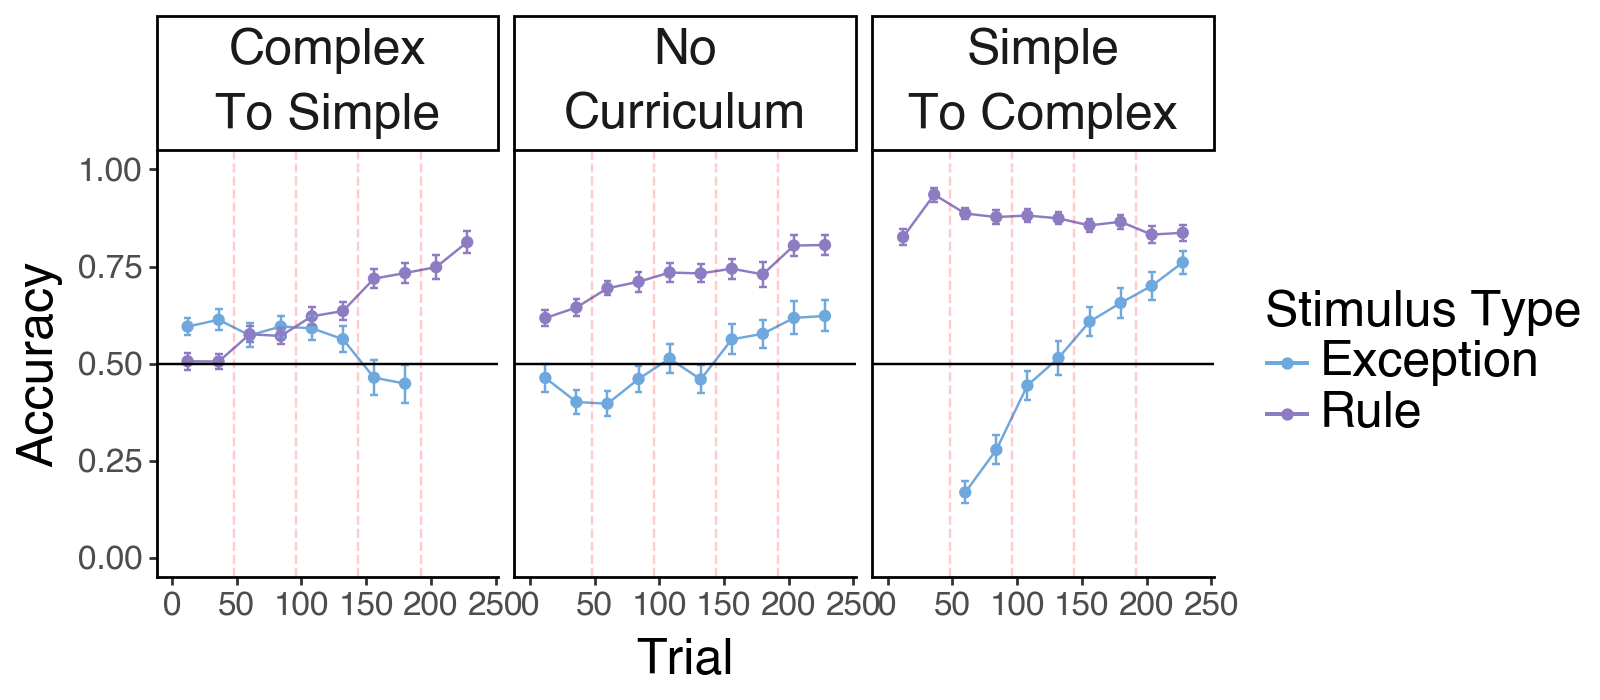

In [44]:
# Bin accuracy over trials of learning and plot by curriculumCondition (with n per condition)
bin_size = 24
df_learning = df[df['taskPart'] == 'learning']
df_learning['total_trial_num'] = (
    df_learning
      .sort_values(['subjectId', 'blockNum', 'trialNum'])
      .groupby('subjectId')
      .cumcount() + 1
)
df_learning = df_learning[df_learning['timeout'] == False]
df_learning['bin'] = ((df_learning['total_trial_num'] - 1) // bin_size) + 1
# Bin mid point for plotting (use trial number in x-axis)
df_learning['bin_mid'] = (df_learning['bin'] * bin_size - bin_size / 2).astype(float)

# Per-subject accuracy per bin
per_sub = (
    df_learning
    .groupby(['curriculum', 'subjectId','stimType', 'bin', 'bin_mid'], as_index=False)
    .agg(acc=('correct', 'mean'))
)

# Across-subject summary: mean and standard error (SE)
summary = (
    per_sub
    .groupby(['curriculum', 'stimType', 'bin', 'bin_mid'], as_index=False)
    .agg(mean_acc=('acc', 'mean'), se=('acc', lambda x: x.std(ddof=1) / np.sqrt(len(x))))
)
# Create ymin/ymax columns for errorbars
summary['ymin'] = summary['mean_acc'] - summary['se']
summary['ymax'] = summary['mean_acc'] + summary['se']

# Compute vertical lines every 48 trials (in trial number space)
max_trial = int(df_learning['total_trial_num'].max())
vlines = list(range(48, max_trial, 48))
# Put vlines into a small DataFrame so plotnine treats them as continuous values
vline_df = pd.DataFrame({'x': vlines}) if len(vlines) > 0 else pd.DataFrame({'x': []})

# Build the plot
p = (
    ggplot(summary, aes(x='bin_mid', y='mean_acc', color='stimType', group='stimType'))
    + geom_line()
    + geom_point()
    + geom_errorbar(aes(ymin='ymin', ymax='ymax'), width=6)
    + facet_wrap('~curriculum')
    + (geom_vline(mapping=aes(xintercept='x'), data=vline_df, color='red', linetype='dashed', alpha=0.2) if not vline_df.empty else 0)
    + geom_hline(yintercept=0.5, linetype='solid', color='black', alpha=1)
    + scale_x_continuous(limits=(0, max_trial))
    + scale_y_continuous(limits=(0, 1))
    + scale_color_manual(values=stimColors)
    + theme_classic()
    + labs(x='Trial', y='Accuracy', color='Stimulus Type')
    + theme(axis_text=element_text(size=12), text=element_text(size=18),figure_size=(8,3.5))
)
p


In [45]:
df_learning['total_trial_num'] = (
    df_learning
      .sort_values(['subjectId', 'blockNum', 'trialNum'])
      .groupby('subjectId')
      .cumcount() + 1
)
df_learning.to_csv('data/exp1_learning.csv', index=False)

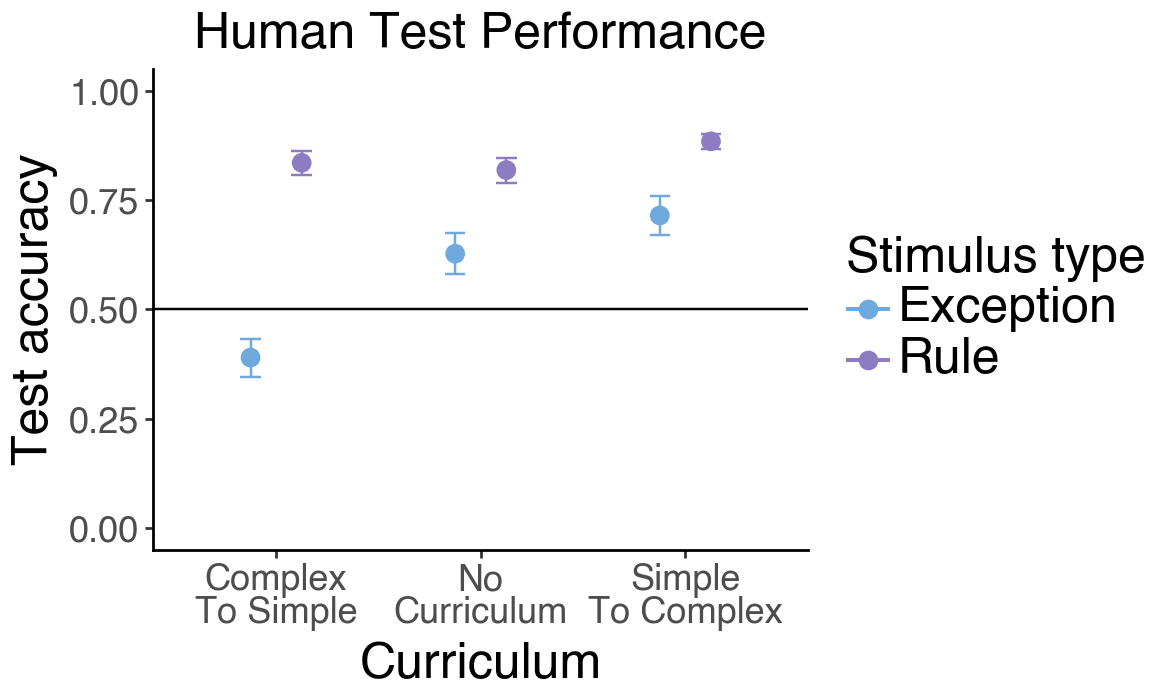

In [46]:
# Plot test-phase accuracy by curriculum and stimType 

test_df = df[(df['taskPart'] == 'test') & (df['timeout'] == False)]

# Per-subject accuracy in the test phase per curriculum and stimType
per_sub_test = (
    test_df
    .groupby(['curriculum','subjectId', 'stimType'], as_index=False)
    .agg(acc=('correct', 'mean'))
)

# Across-subject summary: mean and SE
summary_test = (
    per_sub_test
    .groupby(['curriculum', 'stimType'], as_index=False)
    .agg(mean_acc=('acc', 'mean'), se=('acc', lambda x: x.std(ddof=1) / np.sqrt(len(x))))
)
summary_test['ymin'] = summary_test['mean_acc'] - summary_test['se']
summary_test['ymax'] = summary_test['mean_acc'] + summary_test['se']

# Plot: curriculum on x-axis, accuracy on y-axis, stimType side-by-side
dodge = position_dodge(width=0.5)
p_test = (
    ggplot(summary_test, aes(x='curriculum', y='mean_acc', color='stimType'))
    + geom_point(position=dodge, size=3)
    + geom_errorbar(aes(ymin='ymin', ymax='ymax'), width=0.2, position=dodge)
    + labs(x='Curriculum', y='Test accuracy', color='Stimulus type')
    + scale_y_continuous(limits=(0, 1))
    + scale_color_manual(values=stimColors)
    + theme_classic()
    + geom_hline(yintercept=0.5, linetype='solid', color='black', alpha=1)
    # make x tick labels larger and not tilted
    + theme(axis_text_x=element_text(rotation=0, ha='center', size=11))
    + ggtitle('Human Test Performance')
    + theme(axis_text=element_text(size=13), text=element_text(size=18),figure_size=(5.8,3.5))
)

p_test


In [37]:
per_sub_test.to_csv('data/exp1_test.csv', index=False)